# Predicting Customer Term Deposit Subscription Using Supervised Machine Learning

## 1. Project Overview

### 1.1 Background

### 1.2 Problem Statement

### 1.3 Project Objective

### 1.4 Analytical Questions

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root
PROJECT_ROOT = Path.cwd().parent

# Allow imports from src/
sys.path.append(str(PROJECT_ROOT))

# Import project modules


# Dataset
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank-full.csv"

df = pd.read_csv(DATA_PATH, sep=";")

print(f"Dataset loaded successfully: {df.shape}")

Dataset loaded successfully: (45211, 17)


In [2]:
from src.data_inspection import DataInspection

In [3]:
inspection = DataInspection(df)
inspection.inspect(target="y")

DATASET OVERVIEW
Rows: 45,211
Columns: 17

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

DATA TYPES
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

MISSING VALUES
No standard missing values detected.

PLACEHOLDER VALUES: 'unknown'
      column  count  percentage
3   poutcome  36959       81.75
2    contact  13020       28.80
1  education   1857        4.11
0        job    288        0.64

DUPLICATE RECORDS
Duplicate rows: 0

NUMERICAL SUMMARY
            count         mean          std     min    25%    50%     75%  \
age       45211.0    40.936210 

In [4]:
unknown_summary = inspection.placeholder_values()

unknown_summary


PLACEHOLDER VALUES: 'unknown'
      column  count  percentage
3   poutcome  36959       81.75
2    contact  13020       28.80
1  education   1857        4.11
0        job    288        0.64


,column,count,percentage
3,poutcome,36959,81.75
2,contact,13020,28.80
1,education,1857,4.11
0,job,288,0.64


In [5]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


In [6]:
missing_summary = df.isnull().sum()

print(missing_summary[missing_summary > 0])

Series([], dtype: int64)


In [7]:
# Separate features and target

X = df.drop(columns=["y", "duration"])
y = df["y"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (45211, 15)
Target shape: (45211,)

Features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nTest set:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Training set:
X_train: (36168, 15)
y_train: (36168,)

Test set:
X_test: (9043, 15)
y_test: (9043,)


In [9]:
print("Training target distribution:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTest target distribution:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Test target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [ ]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [11]:
from src.preprocessing import DataPreprocessor

preprocessor_builder = DataPreprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features
)

preprocessor = preprocessor_builder.build_pipeline()

In [12]:
# Test the preprocessing pipeline on the training data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nProcessed data type:", type(X_train_processed))

Original training shape: (36168, 15)
Processed training shape: (36168, 50)
Original test shape: (9043, 15)
Processed test shape: (9043, 50)

Processed data type: <class 'numpy.ndarray'>


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline


# Encode target
target_mapping = {"no": 0, "yes": 1}

y_train_encoded = y_train.map(target_mapping)
y_test_encoded = y_test.map(target_mapping)

print("Encoded target distribution:")
print(y_train_encoded.value_counts())

Encoded target distribution:
y
0    31937
1     4231
Name: count, dtype: int64


In [14]:
# Create baseline model pipelines

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)


random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Three baseline classification pipelines created successfully.")

Three baseline classification pipelines created successfully.


In [15]:
import time

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train, y_train_encoded)

    elapsed_time = time.time() - start_time

    training_times[name] = elapsed_time

    print(f"{name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training Logistic Regression...
Logistic Regression trained successfully.
Training time: 2.19 seconds

Training Decision Tree...
Decision Tree trained successfully.
Training time: 5.01 seconds

Training Random Forest...
Random Forest trained successfully.
Training time: 22.73 seconds


In [16]:
from src.evaluate_models import ModelEvaluator

evaluator = ModelEvaluator(models)

In [17]:
baseline_results = evaluator.evaluate(
    X_test,
    y_test_encoded
)

baseline_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895


In [18]:
confusion_matrices = evaluator.confusion_matrices(
    X_test,
    y_test_encoded
)

for name, matrix in confusion_matrices.items():

    print(f"\n{name}")
    print("-" * 40)
    print(matrix)


Logistic Regression
----------------------------------------
[[7889   96]
 [ 869  189]]

Decision Tree
----------------------------------------
[[7166  819]
 [ 710  348]]

Random Forest
----------------------------------------
[[7835  150]
 [ 811  247]]


In [19]:
# Class-weighted model pipelines

logistic_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


decision_tree_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


random_forest_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

weighted_models = {
    "Logistic Regression (Balanced)": logistic_weighted,
    "Decision Tree (Balanced)": decision_tree_weighted,
    "Random Forest (Balanced)": random_forest_weighted
}

print("Class-weighted model pipelines created successfully.")

Class-weighted model pipelines created successfully.


In [20]:
for name, model in weighted_models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(
        X_train,
        y_train_encoded
    )

    elapsed_time = time.time() - start_time

    print(f"{name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training Logistic Regression (Balanced)...
Logistic Regression (Balanced) trained successfully.
Training time: 5.60 seconds

Training Decision Tree (Balanced)...
Decision Tree (Balanced) trained successfully.
Training time: 4.72 seconds

Training Random Forest (Balanced)...
Random Forest (Balanced) trained successfully.
Training time: 16.23 seconds


In [21]:
weighted_evaluator = ModelEvaluator(weighted_models)

weighted_results = weighted_evaluator.evaluate(
    X_test,
    y_test_encoded
)

weighted_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
1,Decision Tree (Balanced),0.840097,0.308300,0.294896,0.301449,0.603616
2,Random Forest (Balanced),0.880681,0.488268,0.413043,0.447517,0.791260


In [22]:
all_results = pd.concat(
    [
        baseline_results,
        weighted_results
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
3,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
4,Decision Tree (Balanced),0.840097,0.308300,0.294896,0.301449,0.603616
5,Random Forest (Balanced),0.880681,0.488268,0.413043,0.447517,0.791260


In [23]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

print("imbalanced-learn is available.")

imbalanced-learn is available.


In [24]:
categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_features
]

print("Categorical feature indices:")
print(categorical_indices)

print("\nCategorical features:")
print(categorical_features)

Categorical feature indices:
[1, 2, 3, 4, 6, 7, 8, 10, 14]

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline_smote = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Categorical preprocessing
categorical_pipeline_smote = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# Combine preprocessing
smote_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline_smote,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline_smote,
            categorical_features
        )
    ]
)

print("SMOTENC preprocessing components created successfully.")

SMOTENC preprocessing components created successfully.


In [26]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42,
    sampling_strategy="auto"
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train,
    y_train_encoded
)

print("Original training set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train_encoded.shape}")

print("\nAfter SMOTENC:")
print(f"X_train_smote: {X_train_smote.shape}")
print(f"y_train_smote: {y_train_smote.shape}")

print("\nOriginal target distribution:")
print(y_train_encoded.value_counts())

print("\nSMOTENC target distribution:")
print(y_train_smote.value_counts())

Original training set:
X_train: (36168, 15)
y_train: (36168,)

After SMOTENC:
X_train_smote: (63874, 15)
y_train_smote: (63874,)

Original target distribution:
y
0    31937
1     4231
Name: count, dtype: int64

SMOTENC target distribution:
y
0    31937
1    31937
Name: count, dtype: int64


In [27]:
X_train_smote_processed = smote_preprocessor.fit_transform(
    X_train_smote
)

X_test_smote_processed = smote_preprocessor.transform(
    X_test
)

print("Processed SMOTENC training shape:")
print(X_train_smote_processed.shape)

print("\nProcessed test shape:")
print(X_test_smote_processed.shape)

print("\nProcessed data type:")
print(type(X_train_smote_processed))

Processed SMOTENC training shape:
(63874, 50)

Processed test shape:
(9043, 50)

Processed data type:
<class 'numpy.ndarray'>


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

smote_models = {
    "Logistic Regression (SMOTENC)": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree (SMOTENC)": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest (SMOTENC)": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in smote_models.items():
    print(f"Training {name}...")
    model.fit(
        X_train_smote_processed,
        y_train_smote
    )

print("\nAll SMOTENC models trained successfully.")

Training Logistic Regression (SMOTENC)...
Training Decision Tree (SMOTENC)...
Training Random Forest (SMOTENC)...

All SMOTENC models trained successfully.


In [29]:
smote_evaluator = ModelEvaluator(smote_models)

smote_results = smote_evaluator.evaluate(
    X_test_smote_processed,
    y_test_encoded
)

smote_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (SMOTENC),0.725976,0.232278,0.582231,0.332075,0.737570
1,Decision Tree (SMOTENC),0.776291,0.254703,0.473535,0.331240,0.644970
2,Random Forest (SMOTENC),0.836337,0.355479,0.490548,0.412232,0.778564


In [30]:
all_results = pd.concat(
    [
        baseline_results,
        weighted_results,
        smote_results
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
3,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
4,Decision Tree (Balanced),0.840097,0.308300,0.294896,0.301449,0.603616
5,Random Forest (Balanced),0.880681,0.488268,0.413043,0.447517,0.791260
6,Logistic Regression (SMOTENC),0.725976,0.232278,0.582231,0.332075,0.737570
7,Decision Tree (SMOTENC),0.776291,0.254703,0.473535,0.331240,0.644970
8,Random Forest (SMOTENC),0.836337,0.355479,0.490548,0.412232,0.778564


In [31]:
all_results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest (Balanced),0.880681,0.488268,0.413043,0.447517,0.791260
1,Random Forest (SMOTENC),0.836337,0.355479,0.490548,0.412232,0.778564
2,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
3,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
4,Logistic Regression (SMOTENC),0.725976,0.232278,0.582231,0.332075,0.737570
5,Decision Tree (SMOTENC),0.776291,0.254703,0.473535,0.331240,0.644970
6,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
7,Decision Tree (Balanced),0.840097,0.308300,0.294896,0.301449,0.603616
8,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749


In [32]:
all_results.to_csv(
    PROJECT_ROOT / "outputs" / "tables" / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [34]:
from sklearn.metrics import confusion_matrix

top_confusion_matrices = {}

# Random Forest (Balanced)
top_confusion_matrices["Random Forest (Balanced)"] = confusion_matrix(
    y_test_encoded,
    weighted_models["Random Forest (Balanced)"].predict(X_test)
)

# Random Forest (SMOTENC)
top_confusion_matrices["Random Forest (SMOTENC)"] = confusion_matrix(
    y_test_encoded,
    smote_models["Random Forest (SMOTENC)"].predict(
        X_test_smote_processed
    )
)

# Logistic Regression (Balanced)
top_confusion_matrices["Logistic Regression (Balanced)"] = confusion_matrix(
    y_test_encoded,
    weighted_models["Logistic Regression (Balanced)"].predict(X_test)
)

for name, matrix in top_confusion_matrices.items():
    print(f"\n{name}")
    print(matrix)


Random Forest (Balanced)
[[7527  458]
 [ 621  437]]

Random Forest (SMOTENC)
[[7044  941]
 [ 539  519]]

Logistic Regression (Balanced)
[[6166 1819]
 [ 398  660]]


In [35]:
# Get the fitted preprocessing pipeline
rf_balanced = weighted_models["Random Forest (Balanced)"]

preprocessor_fitted = rf_balanced.named_steps["preprocessor"]
rf_model = rf_balanced.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20
feature_importance.head(20)

,Feature,Importance
0,numerical__balance,0.161924
1,numerical__age,0.140301
2,numerical__day,0.122465
3,numerical__campaign,0.067889
4,numerical__pdays,0.040472
5,categorical__poutcome_success,0.034214
6,categorical__contact_unknown,0.026584
7,numerical__previous,0.022258
8,categorical__housing_no,0.017476
9,categorical__housing_yes,0.017450


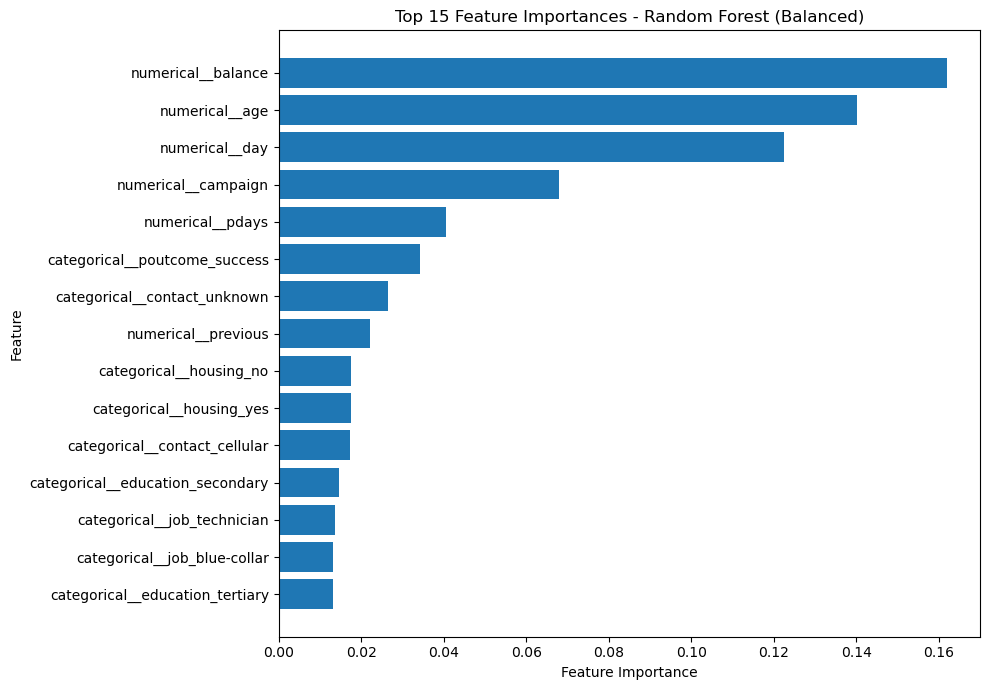

Figure saved to: c:\Users\Tammy\Desktop\Predicting Customer Term Deposit\outputs\figures\random_forest_feature_importance.png


In [36]:
# Select the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 15 Feature Importances - Random Forest (Balanced)"
)

plt.tight_layout()

feature_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "random_forest_feature_importance.png"
)

plt.savefig(
    feature_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {feature_plot_path}")

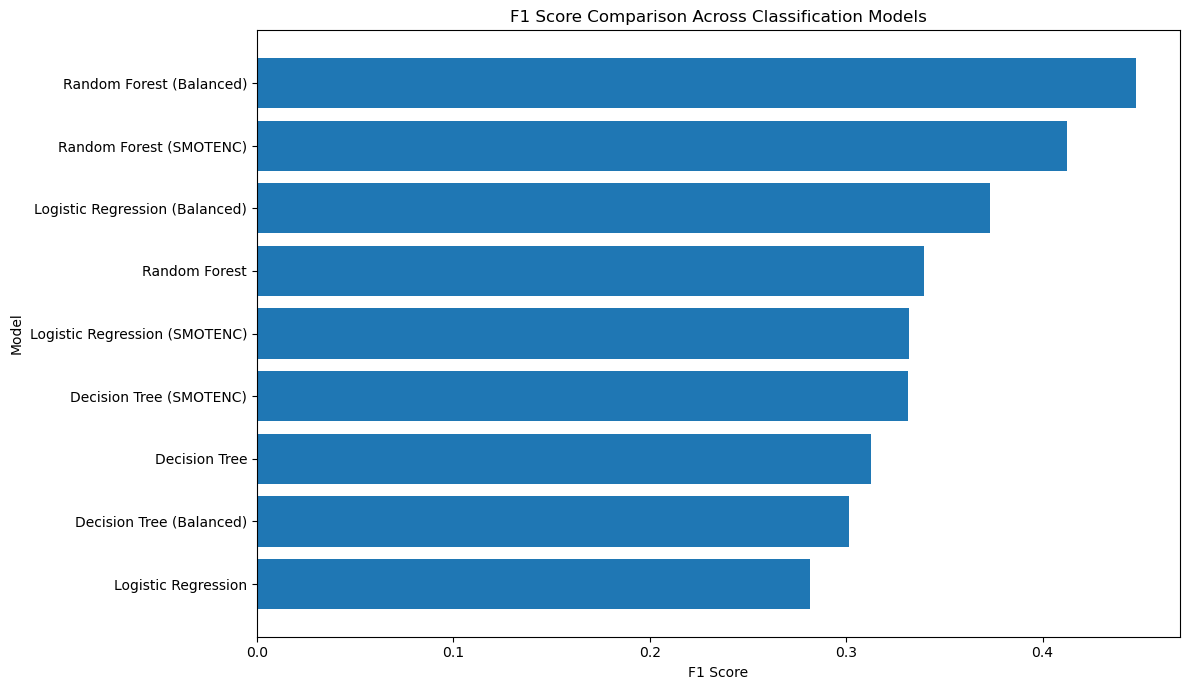

Figure saved to: c:\Users\Tammy\Desktop\Predicting Customer Term Deposit\outputs\figures\model_f1_comparison.png


In [37]:
plt.figure(figsize=(12, 7))

plot_data = all_results.sort_values(
    by="F1 Score",
    ascending=True
)

plt.barh(
    plot_data["Model"],
    plot_data["F1 Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.title("F1 Score Comparison Across Classification Models")

plt.tight_layout()

f1_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "model_f1_comparison.png"
)

plt.savefig(
    f1_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {f1_plot_path}")

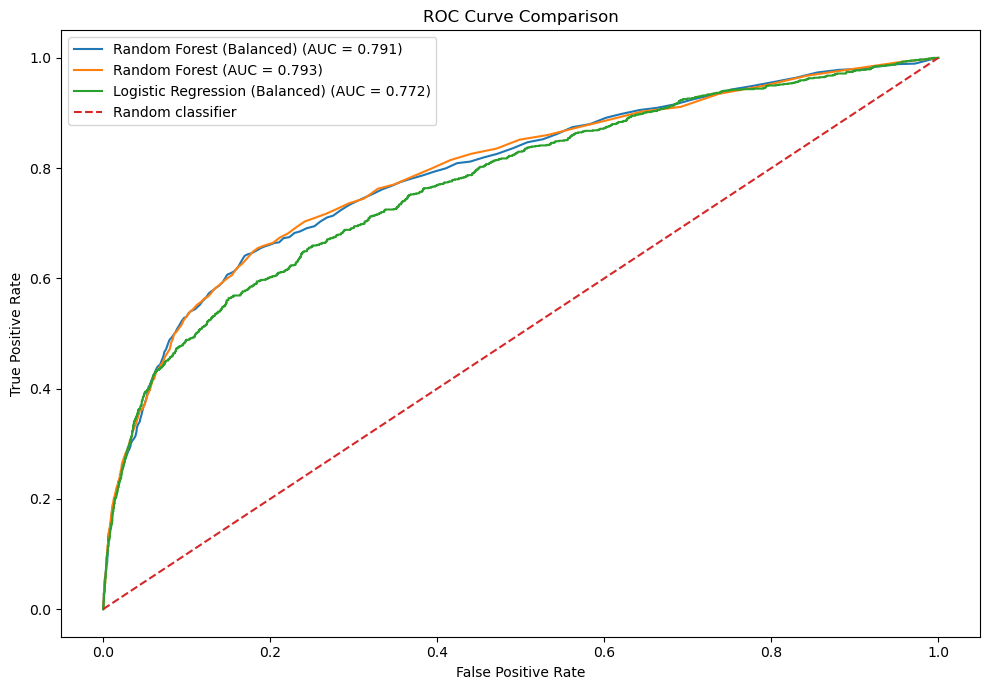

Figure saved to: c:\Users\Tammy\Desktop\Predicting Customer Term Deposit\outputs\figures\roc_curve_comparison.png


In [38]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

# Models that accept raw X_test
roc_models = {
    "Random Forest (Balanced)": (
        weighted_models["Random Forest (Balanced)"],
        X_test
    ),
    "Random Forest": (
        models["Random Forest"],
        X_test
    ),
    "Logistic Regression (Balanced)": (
        weighted_models["Logistic Regression (Balanced)"],
        X_test
    )
}

for name, (model, X_eval) in roc_models.items():

    probabilities = model.predict_proba(X_eval)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test_encoded,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.tight_layout()

roc_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "roc_curve_comparison.png"
)

plt.savefig(
    roc_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {roc_plot_path}")

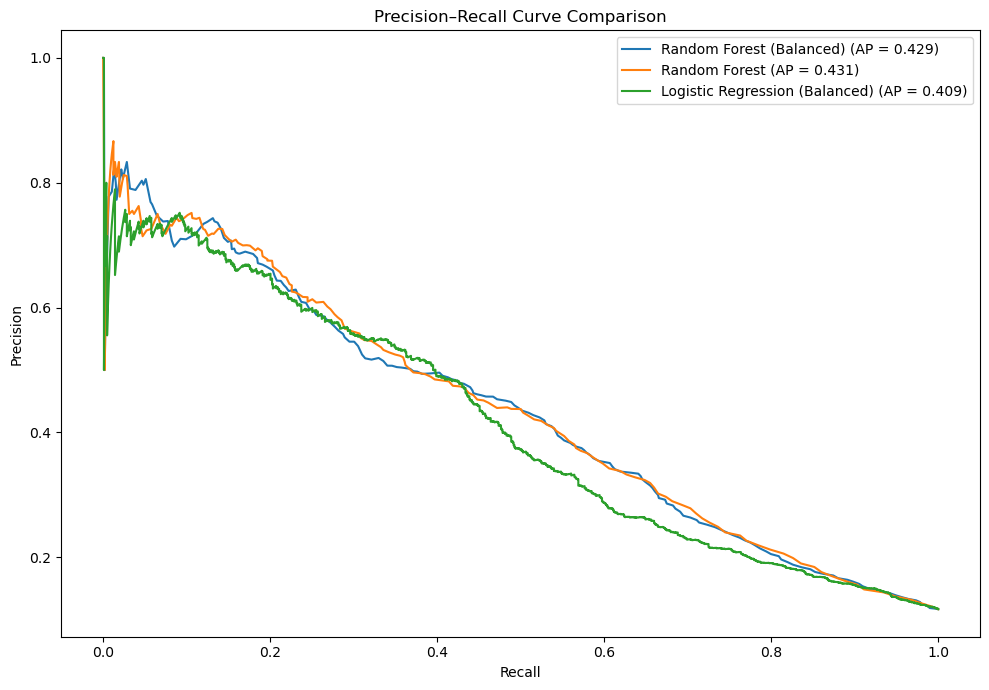

Figure saved to: c:\Users\Tammy\Desktop\Predicting Customer Term Deposit\outputs\figures\precision_recall_comparison.png


In [39]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

pr_models = {
    "Random Forest (Balanced)": (
        weighted_models["Random Forest (Balanced)"],
        X_test
    ),
    "Random Forest": (
        models["Random Forest"],
        X_test
    ),
    "Logistic Regression (Balanced)": (
        weighted_models["Logistic Regression (Balanced)"],
        X_test
    )
}

for name, (model, X_eval) in pr_models.items():

    probabilities = model.predict_proba(X_eval)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test_encoded,
        probabilities
    )

    average_precision = average_precision_score(
        y_test_encoded,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {average_precision:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")

plt.legend()
plt.tight_layout()

pr_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "precision_recall_comparison.png"
)

plt.savefig(
    pr_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {pr_plot_path}")

In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

rf_balanced = weighted_models["Random Forest (Balanced)"]

rf_probabilities = rf_balanced.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_encoded,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_encoded,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_encoded,
            predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,Threshold,Precision,Recall,F1 Score
0,0.30,0.337455,0.619093,0.436812
1,0.35,0.377121,0.567108,0.453001
2,0.40,0.419355,0.528355,0.467587
3,0.45,0.457407,0.466919,0.462114
4,0.50,0.485683,0.416824,0.448627
5,0.55,0.504000,0.357278,0.418142
6,0.60,0.538333,0.305293,0.389626


In [41]:
rf_check_predictions = (
    rf_probabilities >= 0.50
).astype(int)

print("Confusion matrix at threshold 0.50:")
print(
    confusion_matrix(
        y_test_encoded,
        rf_check_predictions
    )
)

print("\nMetrics at threshold 0.50:")
print(
    f"Precision: {precision_score(y_test_encoded, rf_check_predictions):.6f}"
)
print(
    f"Recall: {recall_score(y_test_encoded, rf_check_predictions):.6f}"
)
print(
    f"F1 Score: {f1_score(y_test_encoded, rf_check_predictions):.6f}"
)

Confusion matrix at threshold 0.50:
[[7518  467]
 [ 617  441]]

Metrics at threshold 0.50:
Precision: 0.485683
Recall: 0.416824
F1 Score: 0.448627


In [42]:
rf_direct_predictions = rf_balanced.predict(X_test)

rf_threshold_predictions = (
    rf_probabilities >= 0.50
).astype(int)

print(
    "Predictions identical:",
    np.array_equal(
        rf_direct_predictions,
        rf_threshold_predictions
    )
)

print(
    "Model classes:",
    rf_balanced.named_steps["model"].classes_
)

Predictions identical: False
Model classes: [0 1]


In [43]:
differences = rf_direct_predictions != rf_threshold_predictions

print("Number of different predictions:", differences.sum())

print("\nProbability values for different predictions:")
print(
    rf_probabilities[differences][:20]
)

Number of different predictions: 13

Probability values for different predictions:
[0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


In [44]:
threshold_results_df.to_csv(
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "random_forest_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved successfully.")

Threshold analysis saved successfully.


In [45]:
import joblib

final_model_path = (
    PROJECT_ROOT
    / "outputs"
    / "models"
    / "random_forest_balanced.joblib"
)

joblib.dump(
    rf_balanced,
    final_model_path
)

print(f"Final model saved to: {final_model_path}")

Final model saved to: c:\Users\Tammy\Desktop\Predicting Customer Term Deposit\outputs\models\random_forest_balanced.joblib
